In [ ]:
import numpy as np
import json
import re
from konlpy.tag import Okt
from kiwipiepy import Kiwi
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
from wordcloud import WordCloud
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import matplotlib
import numpy as np
import warnings
import matplotlib
warnings.filterwarnings(action='ignore')
import folium

In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
data_df =  pd.read_csv('./10장_data/CO2 Emissions_Canada.csv', header=0, encoding='CP949', engine='python')
data_df.describe().loc[['max', 'min', 'mean']]

,Engine Size(L),Cylinders,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
max,8.400000,16.00000,30.600000,20.600000,26.100000,69.000000,522.000000
min,0.900000,3.00000,4.200000,4.000000,4.100000,11.000000,96.000000
mean,3.160068,5.61503,12.556534,9.041706,10.975071,27.481652,250.584699


In [6]:
data_df.isna().sum()

Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64

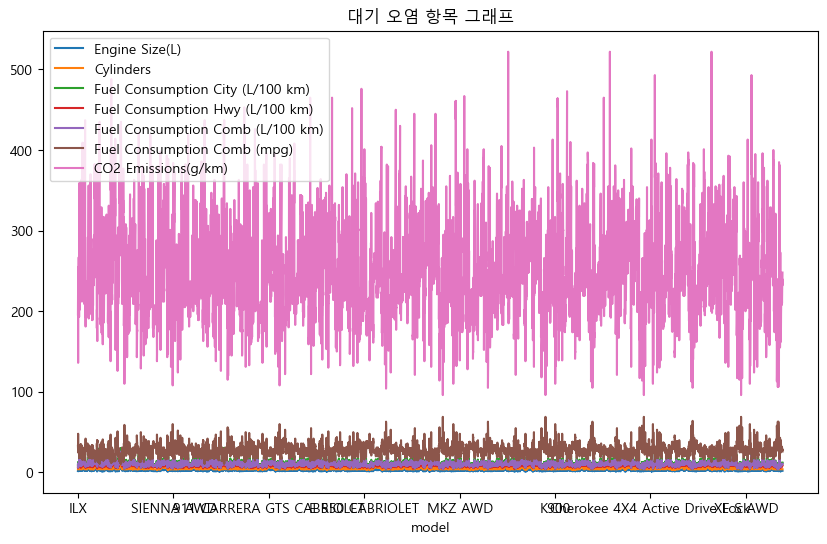

In [9]:
import matplotlib
import matplotlib.pyplot as plt


plt.rc('font', family='Malgun Gothic')

graph_df = data_df.drop(['Make','Vehicle Class'], axis = 1, inplace = False)
graph_df.set_index('Model',inplace=True)
#index를 day로 설정하게 되면 따로 컬럼을 지정해주지 않아도 index를 x축으로 설정하고 plot해준다
graph_df.plot(kind='line', figsize=(10, 6))  # kind='line'으로 선형 그래프 지정

plt.title('대기 오염 항목 그래프')  
plt.xlabel('model')  # x 축 레이블 설정
plt.legend(loc='upper left')  # 범례 위치 설정
plt.show()  

#표준화하는 방법 해당 값에 평균 값들을 빼주고 표준편차로 나누어준다 x-mean(x) / 표준편차
#표준화를 하게 되면 0을 중심으로 뭉쳐서 각각의 변수들이 비슷하게 모인다.
#각각의 변수들의 단위를 지운다?

In [54]:
data_df['Hwy_Efficiency_Ratio'] = data_df['Fuel Consumption Hwy (L/100 km)'] / data_df['Fuel Consumption City (L/100 km)']

In [64]:
#location과 day는 단위를 살려야하기 때문에 drop으로 제외해준다.
data_df2 = data_df.drop(['Make', 'Model', 'Vehicle Class', 'Transmission', 'Fuel Type', 
                      'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)', 
                      'Fuel Consumption Comb (mpg)', 'CO2 Emissions(g/km)'], axis = 1, inplace = False)
#fit_transform을 돌리면 해당 값들이 표준화 된다(정규화는 아니고 표준화이다 -> 정규화는 최종데이터 범위가 0~1사이로 나오게 된다.)
data_df2_scaled = StandardScaler().fit_transform(data_df2.values)
data_df2 = pd.DataFrame(data_df2_scaled , index = data_df.index)
data_df2.columns = ['engine size','cylinders','fuel consumption comb','hwy_consumption']
data_df2.head(2)

,engine size,cylinders,fuel consumption comb,hwy_consumption
0,-0.856721,-0.883408,-0.855742,-0.718046
1,-0.561317,-0.883408,-0.475423,-0.575407


In [65]:
day_df = data_df[['Make', 'Model', 'Vehicle Class', 'Transmission', 'Fuel Type']].copy()
graph_df2 = pd.concat([day_df, data_df2], axis=1)

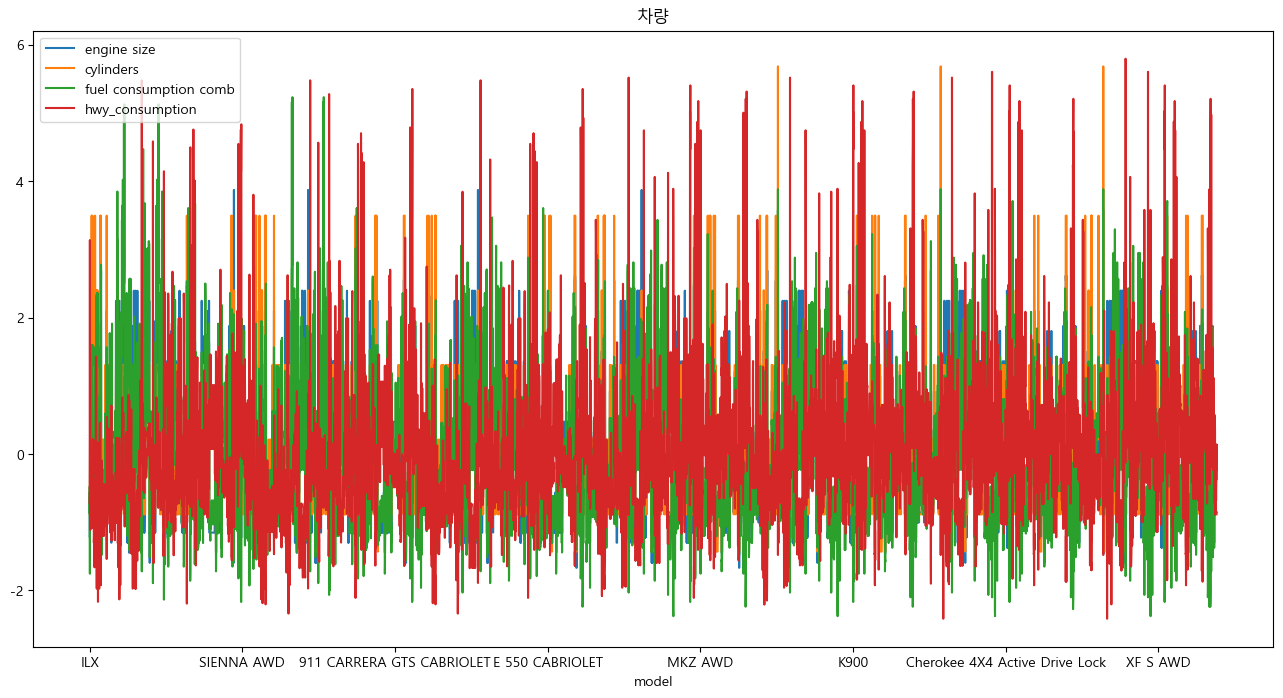

In [66]:
graph_df2.set_index('Model',inplace=True)
graph_df2.plot(kind='line', figsize=(16, 8))  
plt.title('차량')  
plt.xlabel('model')  
plt.legend(loc='upper left')  
plt.rcParams['axes.unicode_minus'] = False   #음수 부호 깨지지 않게 설정 
plt.show() 

In [67]:
Y_co2 = data_df['CO2 Emissions(g/km)']
X = graph_df2.drop(['Make', 'Vehicle Class', 'Transmission', 'Fuel Type'], axis=1, inplace=False)

In [68]:
X_train, X_test, Y_co2_train, Y_co2_test = train_test_split(X, Y_co2, test_size=0.3, random_state=1)

In [69]:
lr_co2 = LinearRegression()

In [70]:
lr_co2.fit(X_train,Y_co2_train);

In [71]:
Y_co2_predict = lr_co2.predict(X_test)

In [72]:
mse = mean_squared_error(Y_co2_test, Y_co2_predict)
rmse = np.sqrt(mse)

print('MSE : {0:.3f}, RMSE : {1:.3f}'.format(mse, rmse))
print('R^2(Variance score) : {0:.3f}'.format(r2_score(Y_co2_test, Y_co2_predict)))

MSE : 414.620, RMSE : 20.362
R^2(Variance score) : 0.877


In [73]:
print('Y_co2 절편 값: ', lr_co2.intercept_)
print('회귀 계수 값: ', np.round(lr_co2.coef_, 1))

Y_co2 절편 값:  250.59218696374583
회귀 계수 값:  [ 7.5 11.4 37.9 -2.1]


In [74]:
coef = pd.Series(data = np.round(lr_co2.coef_, 2), index=X.columns)
coef.sort_values(ascending = False)

fuel consumption comb    37.93
cylinders                11.38
engine size               7.55
hwy_consumption          -2.06
dtype: float64

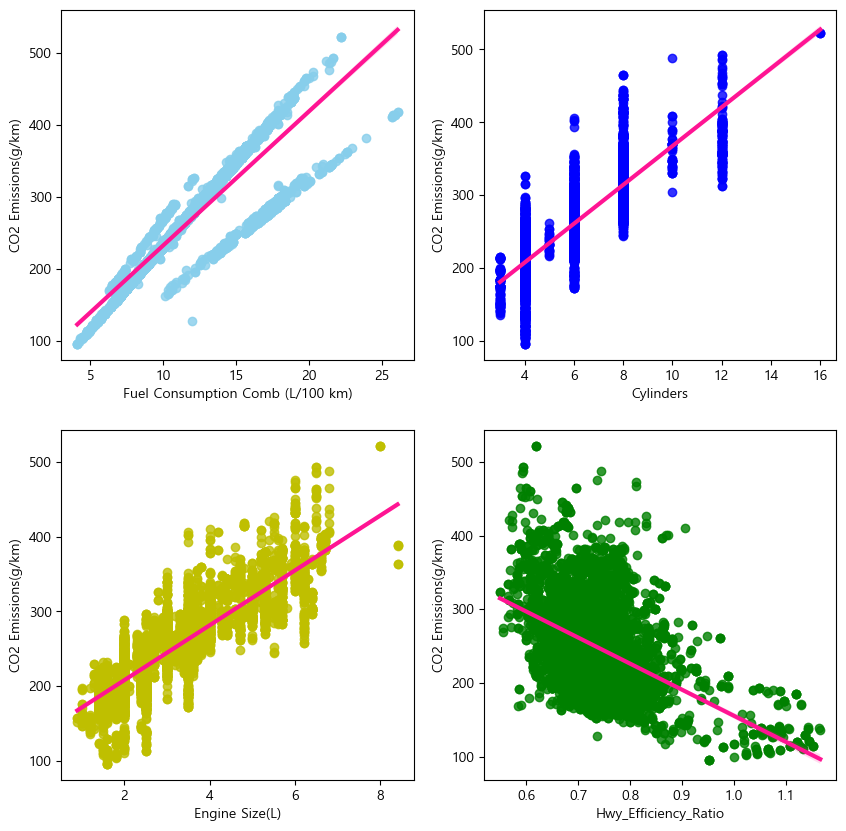

In [78]:
fig, axs = plt.subplots(figsize=(10, 10), ncols=2, nrows=2)
x_features = ['Fuel Consumption Comb (L/100 km)','Cylinders','Engine Size(L)','Hwy_Efficiency_Ratio']
plot_color = ['skyblue', 'b', 'y', 'g', 'r', 'm', 'c', 'k' , 'purple']
for i, feature in enumerate(x_features):
      row = int(i/2)
      col = i%2  
      sns.regplot(x=feature, y='CO2 Emissions(g/km)', data=data_df, ax=axs[row][col],color = plot_color[i],line_kws={'color': 'deeppink', 'lw': 3})

In [52]:
graph_df2.columns

Index(['Make', 'Vehicle Class', 'Transmission', 'Fuel Type', 'engine size',
       'cylinders', 'fuel consumption comb'],
      dtype='object')

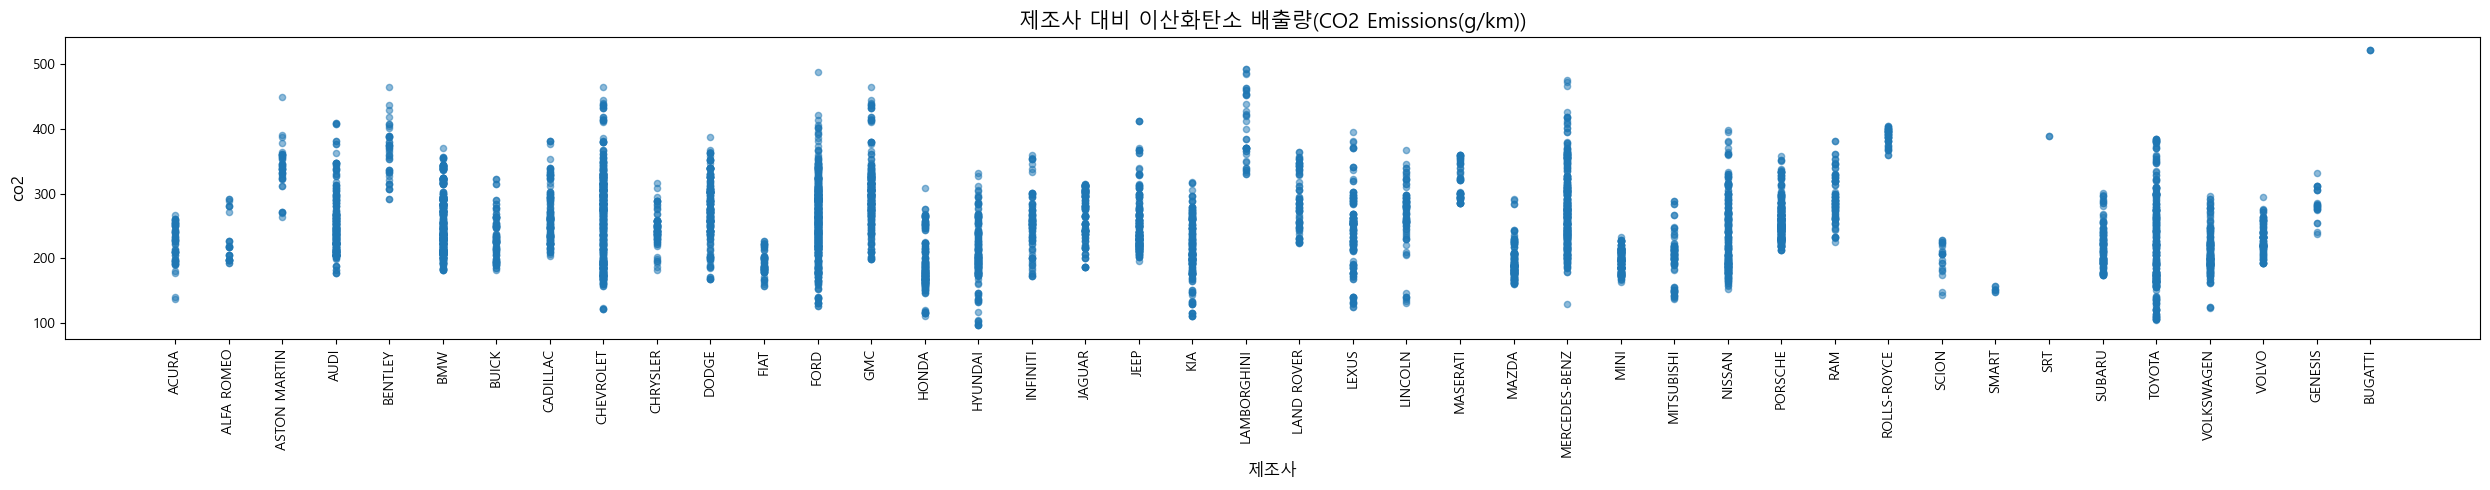

In [81]:
import matplotlib.pyplot as plt

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams["figure.figsize"] = (25, 5)

plt.scatter(data_df['Make'], data_df['CO2 Emissions(g/km)'], s=20, alpha=0.5)

plt.title('제조사 대비 이산화탄소 배출량(CO2 Emissions(g/km))', fontsize=15)
plt.xlabel('제조사', fontsize=12)
plt.ylabel('co2', fontsize=12)


plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

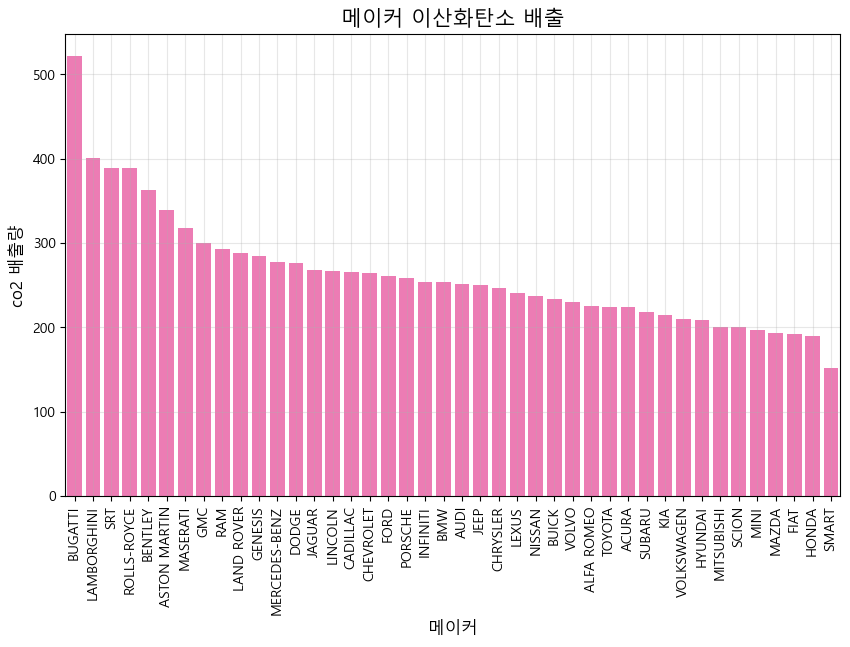

In [92]:
plt.figure(figsize=(10, 6))

# kde=True를 주면 막대그래프 위에 부드러운 분포 곡선선까지 같이 그려줍니다!
rank_order = data_df.groupby('Make')['CO2 Emissions(g/km)'].mean().sort_values(ascending=False).index
sns.barplot( x='Make', y= 'CO2 Emissions(g/km)', data= data_df ,color='hotpink', order = rank_order ,errorbar=None)

plt.title('메이커 이산화탄소 배출', fontsize=15)
plt.xlabel('메이커', fontsize=12)
plt.ylabel('co2 배출량', fontsize=12)
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.show()